# ELECTRIC VEHICLE (EV) ADOPTION ANALYSIS

Performed data cleaning, missing value handling, outlier detection, exploratory data analysis, and visualization on the Electric Vehicle Adoption dataset using Pandas, Matplotlib, and Seaborn.

## Loading Dataset into Python Environment

Imported Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
ev_data=pd.read_csv(r"C:\Users\LENOVO\Desktop\Unique Occassio\DataSets\EV_Adoption_and_Range_Anxiety_Dataset.csv")

Displayed the top 5 rows of the data

In [3]:
ev_data.head()

,Buyer_ID,Age,Gender,Annual_Income_USD,City_Type,Daily_Commute_km,Number_of_Cars_Owned,Current_Car_Type,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Home_Charging_Possible,Environmental_Concern_Level,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,EV00001,56,Male,44906.0,Rural,18.1,1,Truck,1,0,Yes,4.0,Yes,Low,No
1,EV00002,36,Male,88754.0,Rural,5.0,1,SUV,2,3,Yes,1.0,Yes,Low,No
2,EV00003,42,Male,155958.0,Urban,32.2,2,Sedan,14,3,No,2.0,Yes,Medium,Yes
3,EV00004,31,Male,37059.0,Rural,89.9,1,Sedan,2,1,Yes,4.0,No,Low,No
4,EV00005,48,Female,48552.0,Rural,71.0,1,Sedan,2,0,Yes,3.0,Yes,Low,No


Shape of the data

In [4]:
ev_data.shape

(10000, 15)

Statistical summary of data

In [5]:
ev_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,10000.0,46.936200,12.945968,25.0,36.00,47.0,58.00,69.0
Annual_Income_USD,9822.0,85378.485848,32838.684167,30000.0,61369.50,84708.0,107383.25,223345.0
Daily_Commute_km,9819.0,41.105418,23.351276,5.0,23.25,40.2,57.00,135.5
Number_of_Cars_Owned,10000.0,1.859900,0.855421,1.0,1.00,2.0,2.00,4.0
Charging_Stations_Near_Home,10000.0,5.346900,4.049074,0.0,2.00,5.0,8.00,14.0
Charging_Stations_Near_Work,10000.0,7.458200,5.259374,0.0,3.00,6.0,11.00,19.0
Environmental_Concern_Level,9816.0,2.982783,1.413784,1.0,2.00,3.0,4.00,5.0


Information about the data

In [6]:
ev_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Buyer_ID                     10000 non-null  str    
 1   Age                          10000 non-null  int64  
 2   Gender                       10000 non-null  str    
 3   Annual_Income_USD            9822 non-null   float64
 4   City_Type                    10000 non-null  str    
 5   Daily_Commute_km             9819 non-null   float64
 6   Number_of_Cars_Owned         10000 non-null  int64  
 7   Current_Car_Type             10000 non-null  str    
 8   Charging_Stations_Near_Home  10000 non-null  int64  
 9   Charging_Stations_Near_Work  10000 non-null  int64  
 10  Home_Charging_Possible       10000 non-null  str    
 11  Environmental_Concern_Level  9816 non-null   float64
 12  Subsidy_Available            10000 non-null  str    
 13  Range_Anxiety_Level         

Found the number of unique values of each column

In [7]:
ev_data.nunique()

Buyer_ID                       10000
Age                               45
Gender                             3
Annual_Income_USD               8915
City_Type                          3
Daily_Commute_km                 991
Number_of_Cars_Owned               4
Current_Car_Type                   4
Charging_Stations_Near_Home       15
Charging_Stations_Near_Work       20
Home_Charging_Possible             2
Environmental_Concern_Level        5
Subsidy_Available                  2
Range_Anxiety_Level                3
Will_Buy_EV                        2
dtype: int64

Displayed the unique values in each column

In [8]:
for i in ev_data.columns:
    print(i)
    print(ev_data[i].unique())
    print("-"*50)
    print("\n")

Buyer_ID
<ArrowStringArray>
['EV00001', 'EV00002', 'EV00003', 'EV00004', 'EV00005', 'EV00006', 'EV00007',
 'EV00008', 'EV00009', 'EV00010',
 ...
 'EV09991', 'EV09992', 'EV09993', 'EV09994', 'EV09995', 'EV09996', 'EV09997',
 'EV09998', 'EV09999', 'EV10000']
Length: 10000, dtype: str
--------------------------------------------------


Age
[56 36 42 31 48 34 38 65 29 53 25 30 37 54 44 33 59 69 35 68 66 61 60 32
 64 63 43 40 67 58 49 55 45 52 47 51 62 27 28 39 46 50 26 41 57]
--------------------------------------------------


Gender
<ArrowStringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
--------------------------------------------------


Annual_Income_USD
[ 44906.  88754. 155958. ...  97743. 103628.  59052.]
--------------------------------------------------


City_Type
<ArrowStringArray>
['Rural', 'Urban', 'Suburban']
Length: 3, dtype: str
--------------------------------------------------


Daily_Commute_km
[ 18.1   5.   32.2  89.9  71.   75.7  85.4  12.   40.6  42.9  4

## Missing Values

Checking for null values

In [9]:
ev_data.isna().sum()

Buyer_ID                         0
Age                              0
Gender                           0
Annual_Income_USD              178
City_Type                        0
Daily_Commute_km               181
Number_of_Cars_Owned             0
Current_Car_Type                 0
Charging_Stations_Near_Home      0
Charging_Stations_Near_Work      0
Home_Charging_Possible           0
Environmental_Concern_Level    184
Subsidy_Available                0
Range_Anxiety_Level              0
Will_Buy_EV                      0
dtype: int64

Check whether the data distribution is symmetrical or skewed

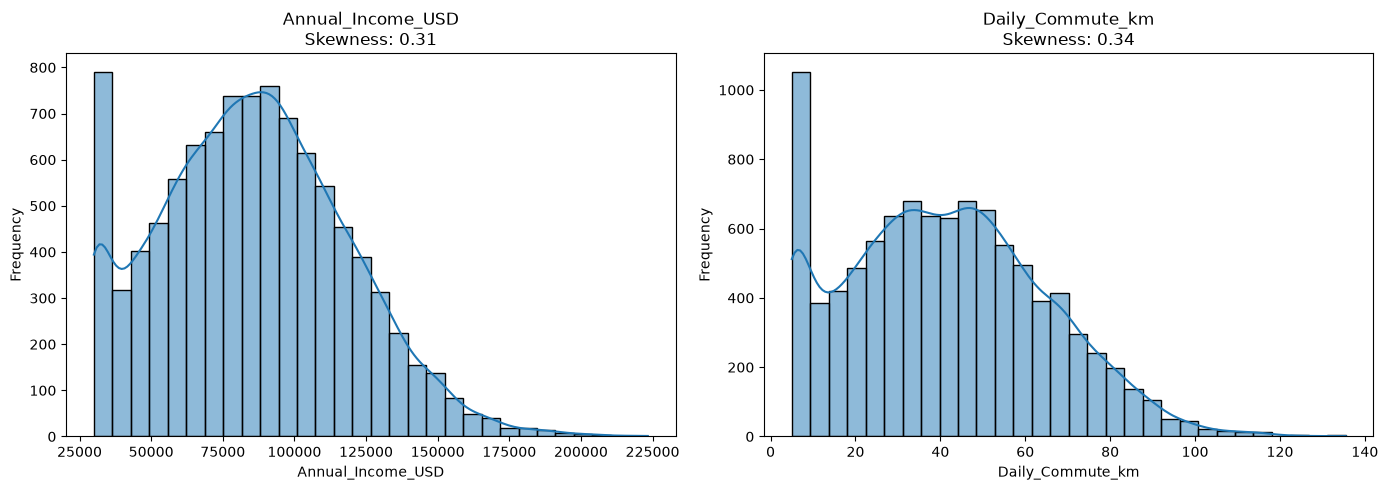

In [10]:
cols = ['Annual_Income_USD', 'Daily_Commute_km']

plt.figure(figsize=(14, 5))

for i, col in enumerate(cols, 1):
    plt.subplot(1, 2, i)

    sns.histplot(ev_data[col], kde=True, bins=30)

    skewness = ev_data[col].skew()

    plt.title(f'{col}\nSkewness: {skewness:.2f}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Since both are positively skewed, missing values can be replaced with median

In [11]:
cols = ['Annual_Income_USD', 'Daily_Commute_km']

for col in cols:
    ev_data[col] = ev_data[col].fillna(ev_data[col].median())

Filled the 'Environmental_Concern_Level' with mod value

In [12]:
# Categorical column - Mode imputation
ev_data['Environmental_Concern_Level'] = ev_data['Environmental_Concern_Level'].fillna(
    ev_data['Environmental_Concern_Level'].mode()[0])

Again checking the null values

In [13]:
ev_data.isna().sum()

Buyer_ID                       0
Age                            0
Gender                         0
Annual_Income_USD              0
City_Type                      0
Daily_Commute_km               0
Number_of_Cars_Owned           0
Current_Car_Type               0
Charging_Stations_Near_Home    0
Charging_Stations_Near_Work    0
Home_Charging_Possible         0
Environmental_Concern_Level    0
Subsidy_Available              0
Range_Anxiety_Level            0
Will_Buy_EV                    0
dtype: int64

### Successfully handled all the null values

## Correlaton Matrix

In [14]:
# Converting target column into numerical column to find the relation between other columns using correlation matrix
ev_data['Will_Buy_EV'] = ev_data['Will_Buy_EV'].map({
    'Yes': 1,
    'No': 0
})

<Axes: >

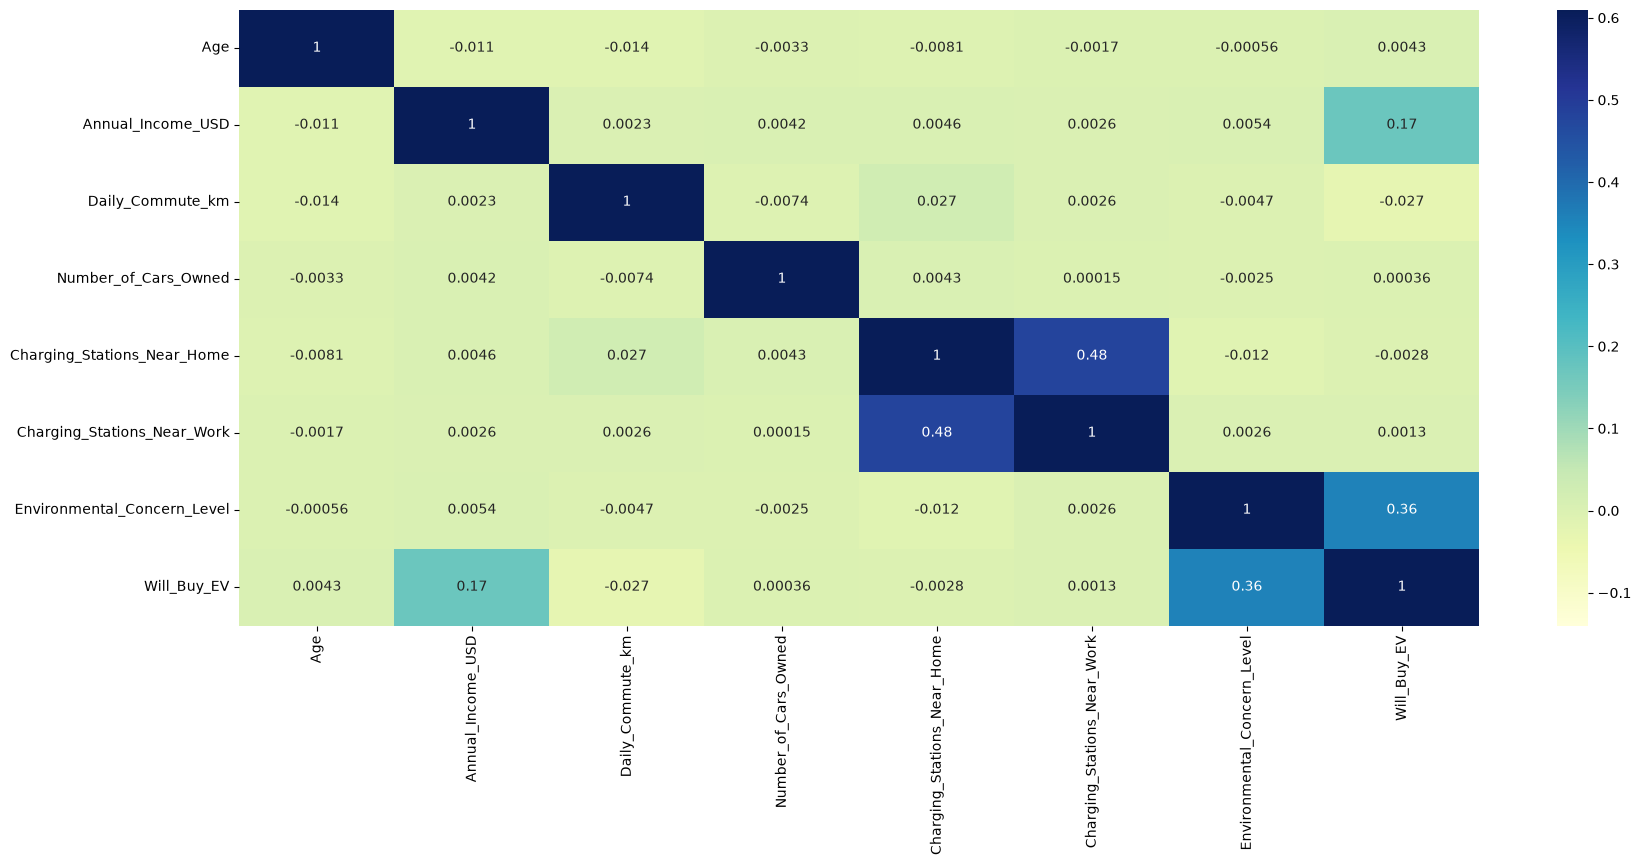

In [15]:
# Select numerical columns
numeric_data = ev_data.select_dtypes(include='number')

# Correlaton Matrix
corrmatrix=numeric_data.corr()
plt.subplots(figsize=(20,8))
sns.heatmap(corrmatrix,annot=True,vmin=-0.14,vmax=0.61,cmap='YlGnBu')

## Feature Engineering

Dropping irrelevent Columns

In [16]:
ev_data.drop(['Buyer_ID','Age','Daily_Commute_km','Number_of_Cars_Owned','Charging_Stations_Near_Home','Charging_Stations_Near_Work'], axis=1, inplace=True)

In [17]:
ev_data.head()

,Gender,Annual_Income_USD,City_Type,Current_Car_Type,Home_Charging_Possible,Environmental_Concern_Level,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,Male,44906.0,Rural,Truck,Yes,4.0,Yes,Low,0
1,Male,88754.0,Rural,SUV,Yes,1.0,Yes,Low,0
2,Male,155958.0,Urban,Sedan,No,2.0,Yes,Medium,1
3,Male,37059.0,Rural,Sedan,Yes,4.0,No,Low,0
4,Female,48552.0,Rural,Sedan,Yes,3.0,Yes,Low,0


## Outlier Handling

Checking Outliers

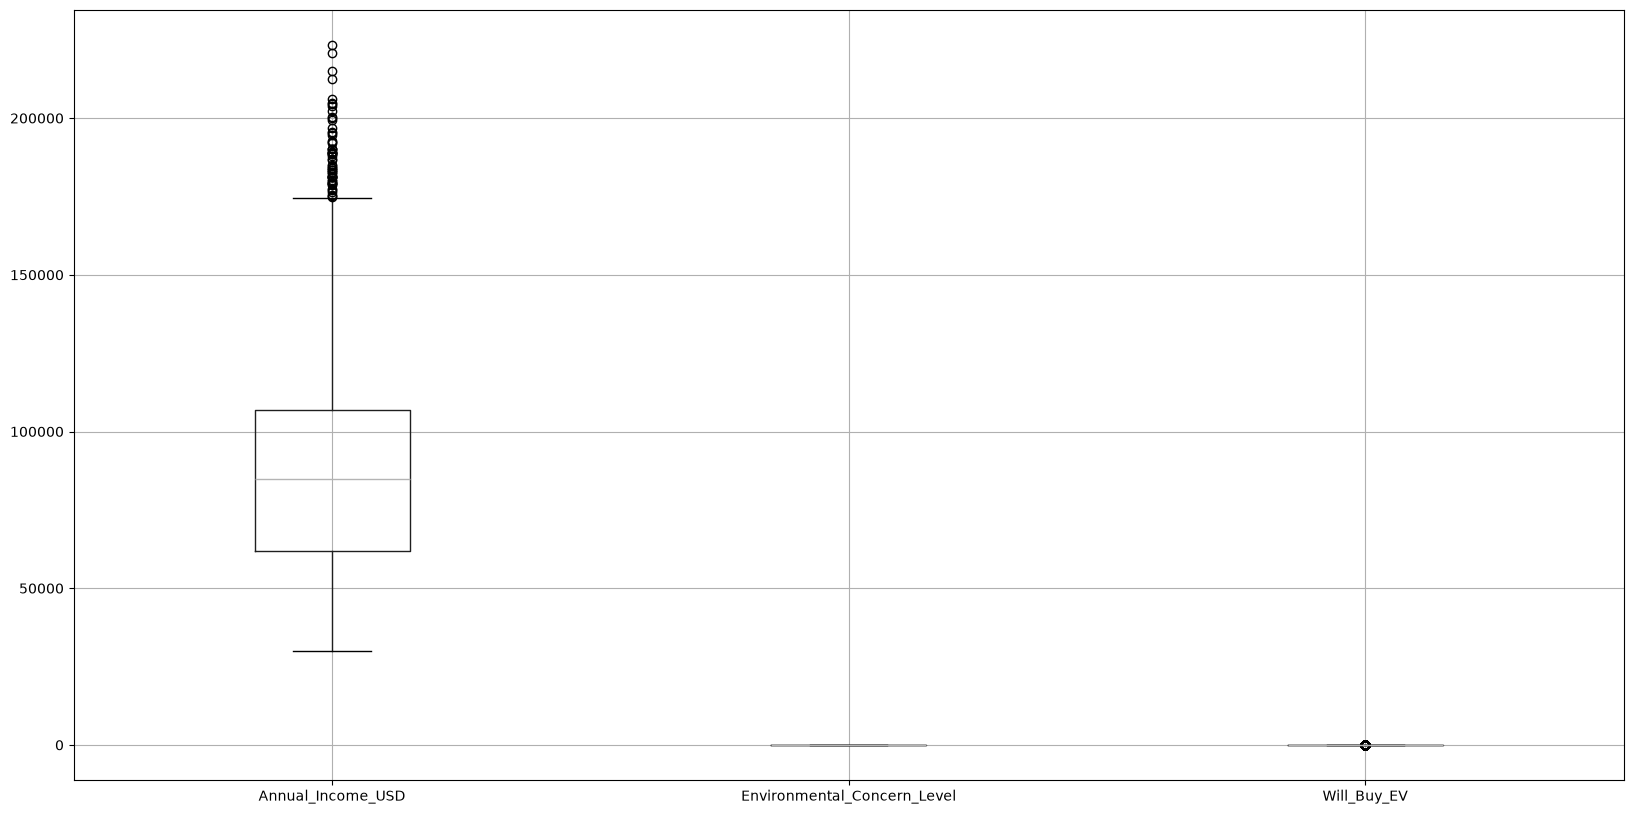

In [18]:
plt.figure(figsize=(20,10))
ev_data.boxplot()
plt.show()

In [19]:
q1=ev_data['Annual_Income_USD'].quantile(0.25)
q3=ev_data['Annual_Income_USD'].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
ev_data['Annual_Income_USD']=ev_data['Annual_Income_USD'].clip(upper,lower)

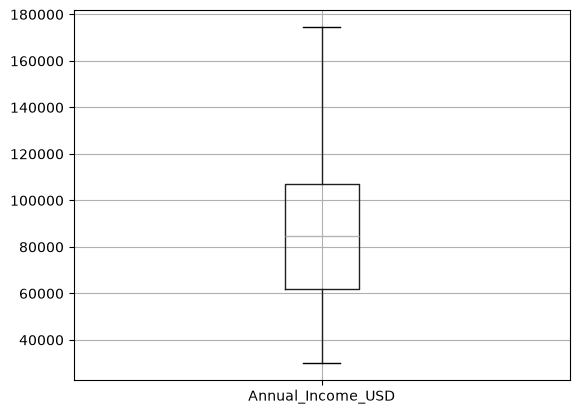

In [20]:
ev_data.boxplot(column='Annual_Income_USD')
plt.show()

Successfully handled outlier person income

## Data Visualization

### Univarite Analysis

In [21]:
# Set a consistent plotting style
sns.set_theme(style="white", palette="tab10")

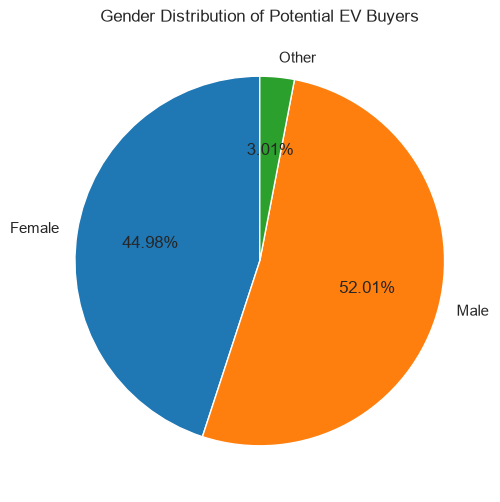

In [22]:
plt.figure(figsize=(6,6))

ev_data['Gender'].value_counts().sort_index().plot(
    kind='pie',
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Gender Distribution of Potential EV Buyers')
plt.show()

* 52.01% of the Buyers are male
* 44.98% of the Buyers are female
* 3.01% of the Buysers include in other category

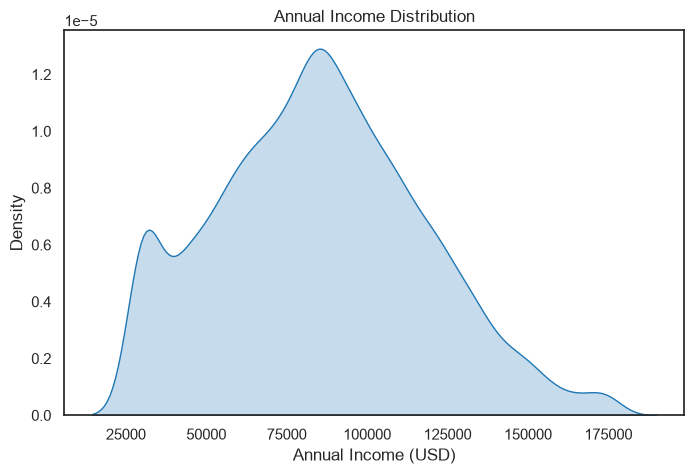

In [23]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=ev_data, x='Annual_Income_USD',
            fill=True)
plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (USD)')
plt.ylabel('Density')
plt.show()

* The average income of the buyers is in between 75000 and 1 lakh

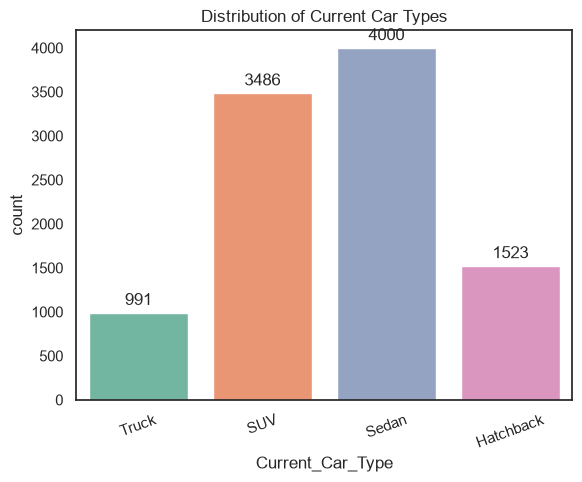

In [24]:
ax=sns.countplot(
    data=ev_data,
    x='Current_Car_Type',
    hue='Current_Car_Type',
    palette='Set2',
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Distribution of Current Car Types')
plt.xticks(rotation=20)
plt.show()

* Mainly four type of cars are used by the buyers.
* Most buyers, around 4000 uses Sedan
* Secondmost car used by the buyers is SUV, and is used by 3486 buyers
* 1523 buyers uses hatchback
* 991 buyers uses truck

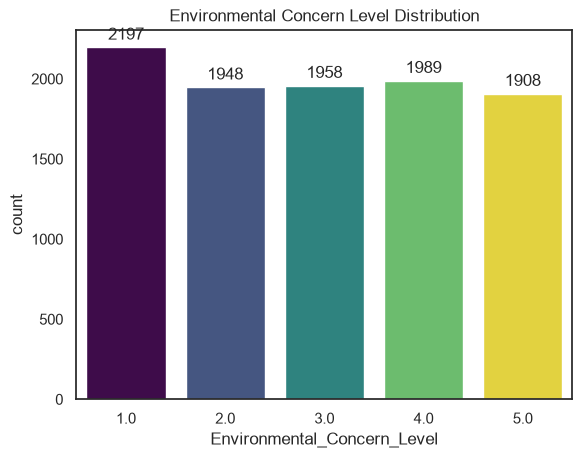

In [25]:
ax=sns.countplot(
    data=ev_data,
    x='Environmental_Concern_Level',
    hue='Environmental_Concern_Level',
    palette='viridis',
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Environmental Concern Level Distribution')
plt.show()

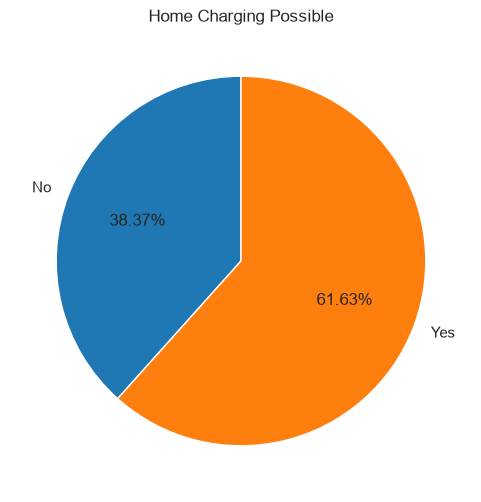

In [26]:
plt.figure(figsize=(6,6))

ev_data['Home_Charging_Possible'].value_counts().sort_index().plot(
    kind='pie',
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Home Charging Possible')
plt.show()

* Around 61.63% of the buyers have home charging possibility
* Only 38.37% of buys didn't have charging facility at home

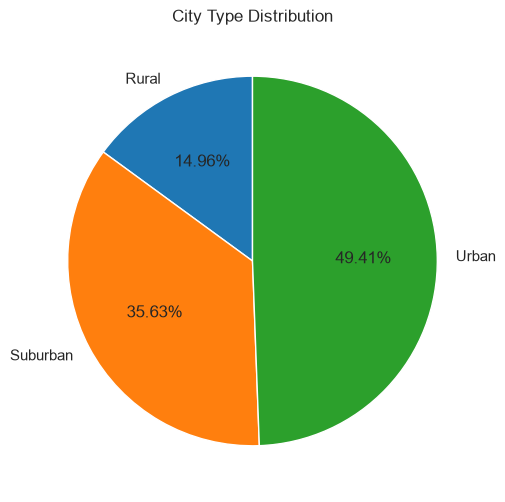

In [27]:
plt.figure(figsize=(6,6))

ev_data['City_Type'].value_counts().sort_index().plot(
    kind='pie',
    autopct='%1.2f%%',
    startangle=90
)

plt.title('City Type Distribution')
plt.show()

* Urban participants represent the largest group.
* Suburban participants form the second-largest group.
* Rural participants are comparatively fewer.

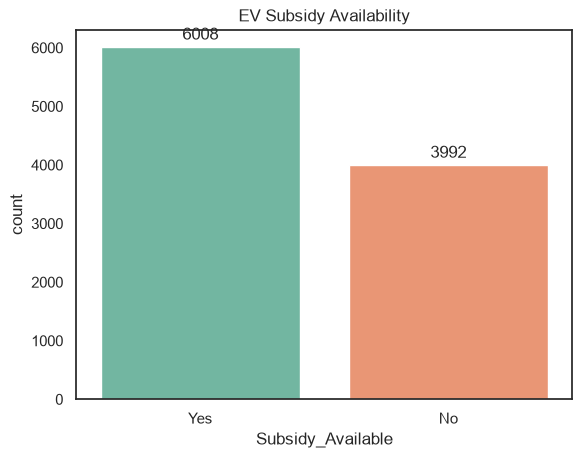

In [28]:
ax=sns.countplot(
    data=ev_data,
    x='Subsidy_Available',
    hue='Subsidy_Available',
    palette='Set2',
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')
plt.title('EV Subsidy Availability')
plt.show()

* Around 6008 buyers get subsidy while buying ev(60.08%).
* 3993 buyers are not getting any subsidies.

### Bivariate analysis

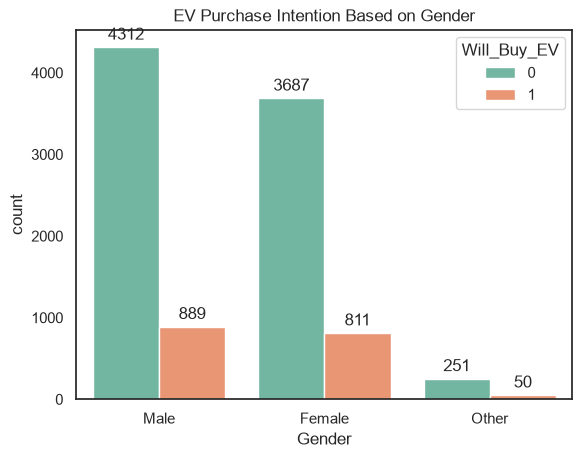

In [29]:
ax=sns.countplot(
    data=ev_data,
    x='Gender',
    hue='Will_Buy_EV',
    palette='Set2'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')
plt.title('EV Purchase Intention Based on Gender')
plt.show()

* Around 1/5 of all gender categories are only willing to buy ev.
* Female - 18%
* Male - 17.1%
* Other - 16.6%
* So there is no big change in the participats according to gender

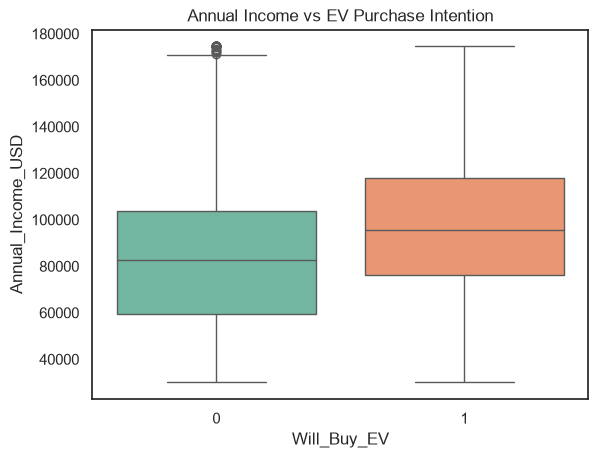

In [30]:
sns.boxplot(
    data=ev_data,
    x='Will_Buy_EV',
    y='Annual_Income_USD',
    hue='Will_Buy_EV',
    palette='Set2',
    legend=False
)
plt.title('Annual Income vs EV Purchase Intention')
plt.show()

* Participants intending to purchase EVs have a higher average annual income than those who do not.

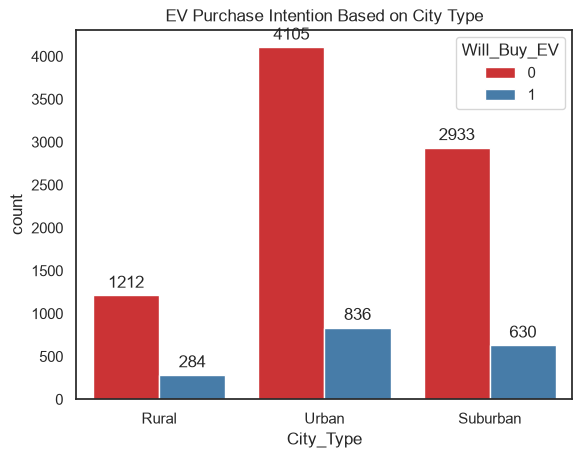

In [31]:
ax=sns.countplot(
    data=ev_data,
    x='City_Type',
    hue='Will_Buy_EV',
    palette='Set1'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('EV Purchase Intention Based on City Type')
plt.show()

* Rural - 19.0%
* Suburban - 17.7%
* Urban - 16.9 %
* Buyers within the rural area are more interested in buying ev.
* Even though the changes are very small to compare

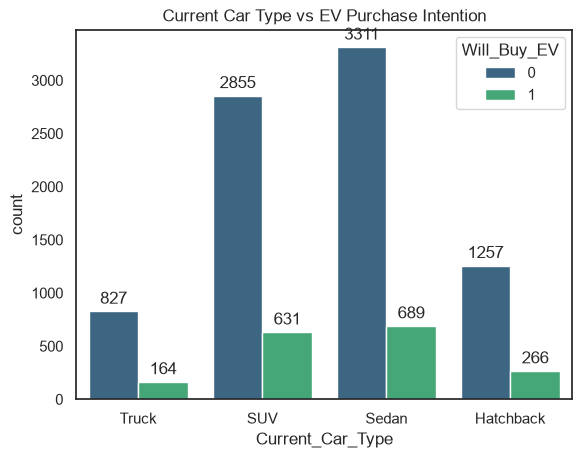

In [32]:
ax=sns.countplot(
    data=ev_data,
    x='Current_Car_Type',
    hue='Will_Buy_EV',
    palette='viridis'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Current Car Type vs EV Purchase Intention')
plt.show()

* SUV - 18.1%
* Hatchback - 17.5%
* Sedan - 17.2%
* Truck - 16.5%
* SUV owners show the highest purchase intention, while truck owners show the lowest.
* However, the differences are relatively small.

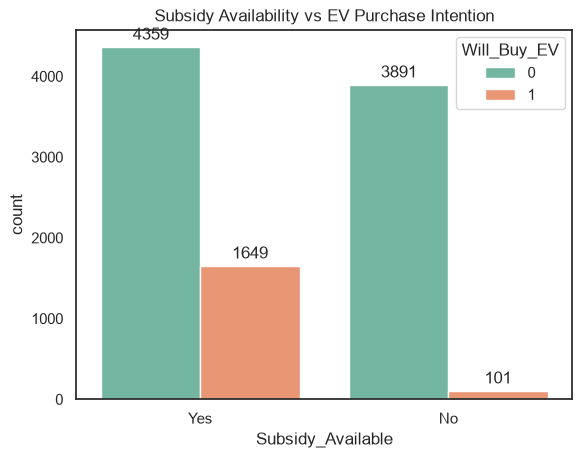

In [33]:
ax=sns.countplot(
    data=ev_data,
    x='Subsidy_Available',
    hue='Will_Buy_EV',
    palette='Set2'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Subsidy Availability vs EV Purchase Intention')
plt.show()

* Participants with subsidy availability have a 27.4% purchase intention rate.
* Participants without subsidy availability have only a 2.5% purchase intention rate.

##### Subsidy availability appears to be one of the strongest categorical indicators of EV purchase intention in your dataset

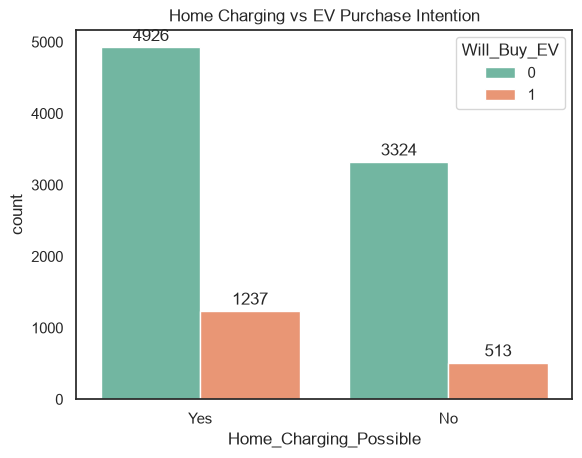

In [34]:
ax=sns.countplot(
    data=ev_data,
    x='Home_Charging_Possible',
    hue='Will_Buy_EV',
    palette='Set2'
)
for container in ax.containers:
    ax.bar_label(container, padding=2, fmt='%d')

plt.title('Home Charging vs EV Purchase Intention')
plt.show()

* People with home charging availability have a 20.1% purchase intention rate.
* People without home charging availability have a 13.4% purchase intention rate.
* The difference is approximately 6.7 percentage points.

##### This indicates that home charging availability is an important potential factor in EV adoption.

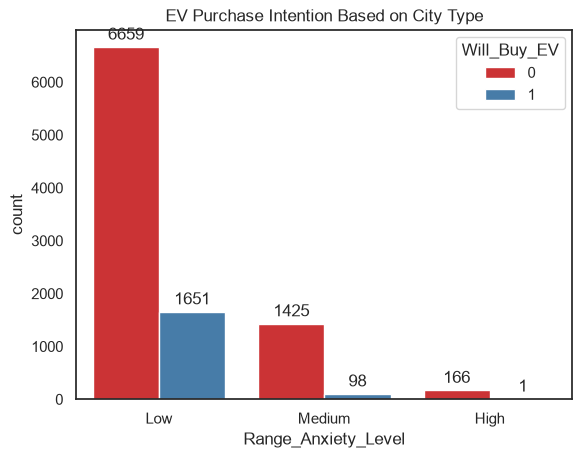

In [35]:
ax=sns.countplot(
    data=ev_data,
    x='Range_Anxiety_Level',
    hue='Will_Buy_EV',
    palette='Set1'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('EV Purchase Intention Based on City Type')
plt.show()

* Low - 19.9%
* Medium - 6.4%
* Low - 0.6%
* Low range anxiety is associated with the highest purchase intention.
* Medium range anxiety has a much lower purchase rate.



High range anxiety has the lowest purchase rate.

### Multivariate analysis

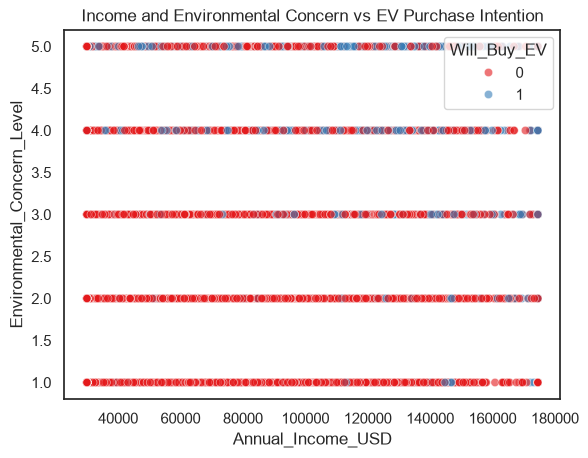

In [36]:
sns.scatterplot(
    data=ev_data,
    x='Annual_Income_USD',
    y='Environmental_Concern_Level',
    hue='Will_Buy_EV',
    palette='Set1',
    alpha=0.6
)

plt.title('Income and Environmental Concern vs EV Purchase Intention')
plt.show()

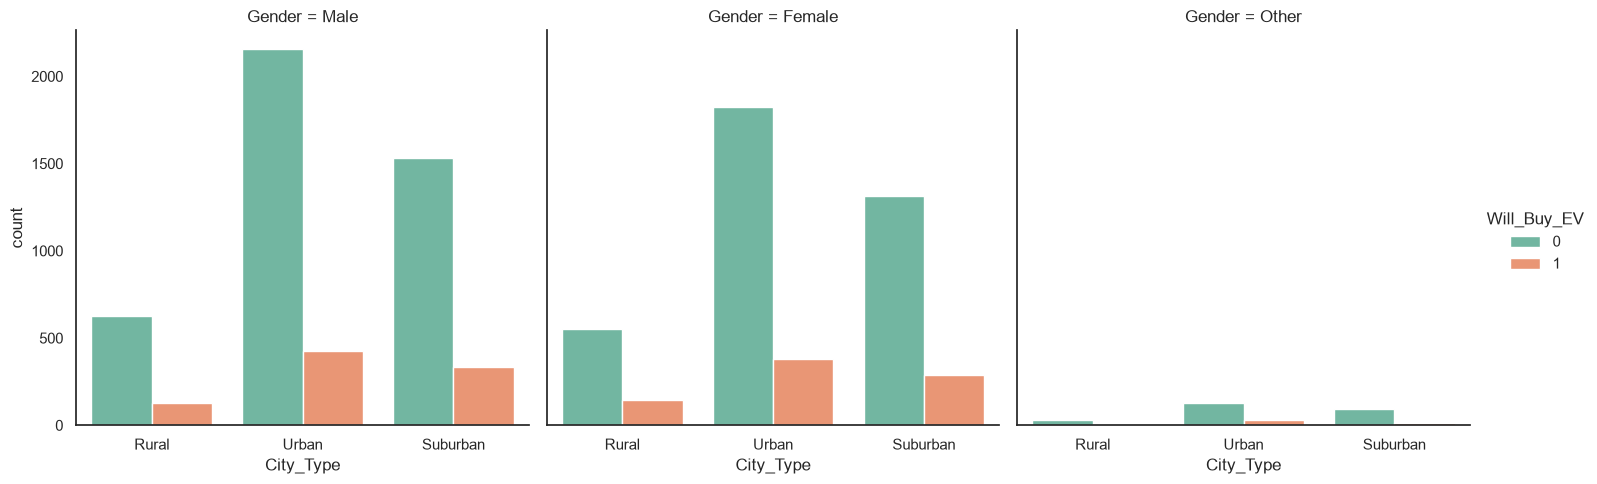

In [37]:
sns.catplot(
    data=ev_data,
    x='City_Type',
    hue='Will_Buy_EV',
    col='Gender',
    kind='count',
    palette='Set2'
)
plt.show()

* Female buyers shows more willingness to buy ev in rural,suburban and rural areas

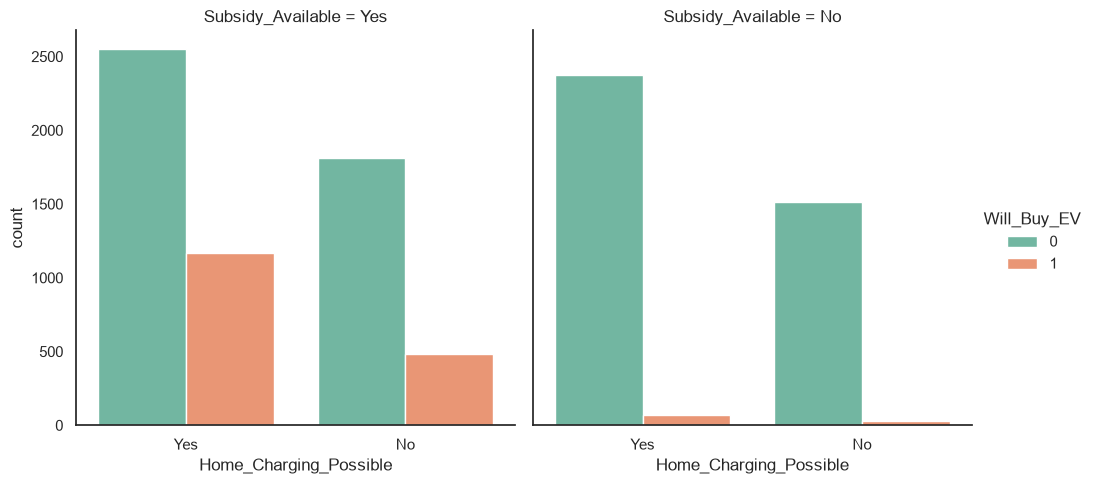

In [38]:
sns.catplot(
    data=ev_data,
    x='Home_Charging_Possible',
    hue='Will_Buy_EV',
    col='Subsidy_Available',
    kind='count',
    palette='Set2'
)

plt.show()

* Most of the buyers are interested in buying EV within the subsidy

## Conclusion

* EV purchase intention is higher among participants with government subsidy availability (27.4%).
* Home charging availability increases purchase intention from 13.4% to 20.
* Participants with higher annual income show greater interest in purchasing EVs.
* Lower range anxiety is associated with higher EV purchase intention.
* SUV owners show the highest purchase intention (18.1%) among vehicle categories.
* Gender has minimal influence on EV purchase intention.